# PyTorch to ONNX Conversion and Ensemble Testing

This notebook provides a comprehensive pipeline for:
1. Converting PyTorch models to ONNX format
2. Creating virtual ensembles from multiple models
3. Testing ensemble performance on validation data
4. Generating performance reports

## Configuration
Update the paths below to match your setup:


In [9]:
! ls -lh /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/results/5class_ensemble


total 158464
-rw-r--r--  1 alokdwivedi  staff   134K Feb  4 18:58 confusion_matrix.png
-rw-r--r--  1 alokdwivedi  staff    12M Feb  4 18:58 conservative_mobilenetv3.onnx
-rw-r--r--  1 alokdwivedi  staff    12M Feb  4 18:58 conservative_mobilenetv3.pth
-rw-r--r--  1 alokdwivedi  staff    12M Feb  4 18:58 ensemble_model_1.pth
-rw-r--r--  1 alokdwivedi  staff    12M Feb  4 18:58 ensemble_model_2.pth
-rw-r--r--  1 alokdwivedi  staff    13M Feb  4 18:58 ensemble_model_3.pth
-rw-r--r--  1 alokdwivedi  staff   351B Feb  4 18:58 evaluation_results.json
-rw-r--r--  1 alokdwivedi  staff    32B Feb  4 18:58 labels.txt
drwxr-xr-x  6 alokdwivedi  staff   192B Feb  4 18:58 onnx_ensemble_output
-rw-r--r--  1 alokdwivedi  staff    14M Feb  4 18:58 oral_cavity_classifier_traced.pth
-rw-r--r--  1 alokdwivedi  staff   219K Feb  4 18:58 training_curves.png


In [14]:
# Configuration
import os
from pathlib import Path

# Paths - Update these to match your setup
PYTORCH_MODELS_DIR = "/Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/results/5class_ensemble"
TEST_DATA_DIR = "/Users/alokdwivedi/dev/oral_cavity_5class_dataset/test"
OUTPUT_DIR = os.path.join(PYTORCH_MODELS_DIR, "onnx_ensemble_output")
SAMPLE_IMAGES_DIR = "./sample_images"

# Create output directories
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(SAMPLE_IMAGES_DIR, exist_ok=True)

print(f"✅ Configuration loaded")
print(f"📁 PyTorch models: {PYTORCH_MODELS_DIR}")
print(f"📁 Test data: {TEST_DATA_DIR}")
print(f"📁 Output: {OUTPUT_DIR}")


✅ Configuration loaded
📁 PyTorch models: /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/results/5class_ensemble
📁 Test data: /Users/alokdwivedi/dev/oral_cavity_5class_dataset/test
📁 Output: /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/results/5class_ensemble/onnx_ensemble_output


## 1. Setup

In [15]:
# Install required packages
# !pip install torch torchvision onnx onnxruntime pillow opencv-python numpy pandas matplotlib seaborn scikit-learn tqdm


In [16]:

# Import libraries
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import onnx
import onnxruntime as ort
from PIL import Image
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tqdm import tqdm
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print("✅ All dependencies loaded successfully")
print(f"🔥 PyTorch version: {torch.__version__}")
print(f"🔥 ONNX version: {onnx.__version__}")
print(f"🔥 ONNX Runtime version: {ort.__version__}")


✅ All dependencies loaded successfully
🔥 PyTorch version: 2.10.0
🔥 ONNX version: 1.20.1
🔥 ONNX Runtime version: 1.23.2


In [17]:
# Device setup
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print(f"🍎 Using Apple Silicon GPU (MPS): {device}")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(f"🚀 Using CUDA GPU: {device}")
else:
    device = torch.device('cpu')
    print(f"💻 Using CPU: {device}")

🍎 Using Apple Silicon GPU (MPS): mps


## 2. Discover PyTorch Models


In [18]:
def discover_pytorch_models(models_dir):
    """Discover all PyTorch model files in the directory"""
    models_dir = Path(models_dir)
    
    # Look for common PyTorch model extensions
    model_extensions = ['.pth', '.pt', '.pkl', '.ckpt']
    model_files = []
    
    for ext in model_extensions:
        model_files.extend(list(models_dir.glob(f"**/*{ext}")))
    
    print(f"🔍 Found {len(model_files)} PyTorch model files:")
    for i, model_file in enumerate(model_files, 1):
        print(f"  {i}. {model_file.name} ({model_file.parent.name})")
    
    return model_files

# Discover models
pytorch_models = discover_pytorch_models(PYTORCH_MODELS_DIR)

if not pytorch_models:
    print("❌ No PyTorch models found. Please check the path.")
else:
    print(f"\n✅ Total {len(pytorch_models)} models that can be converted to ONNX")


🔍 Found 5 PyTorch model files:
  1. ensemble_model_3.pth (5class_ensemble)
  2. ensemble_model_2.pth (5class_ensemble)
  3. ensemble_model_1.pth (5class_ensemble)
  4. oral_cavity_classifier_traced.pth (5class_ensemble)
  5. conservative_mobilenetv3.pth (5class_ensemble)

✅ Total 5 models that can be converted to ONNX


## 3. Method to convert from Pytorhc to ONNX 

In [22]:
# �� **Direct PyTorch → Mobile Conversion Functions**

import torch
import torch.nn as nn
from torchvision import models
from pathlib import Path

def convert_pytorch_to_onnx_optimized(pytorch_model_path, onnx_model_path, device, input_shape=(1, 3, 224, 224)):
    """Convert PyTorch ensemble models to ONNX format with correct model loading"""

    # Convert strings to Path objects if needed
    pytorch_model_path = Path(pytorch_model_path)
    onnx_model_path = Path(onnx_model_path)
    
    if onnx_model_path.exists():
        print(f"⏭️ ONNX already exists: {onnx_model_path.name} — skipping conversion")
        return True
    
    print(f"🔄 Converting {pytorch_model_path.name} to ONNX...")
    
    try:
        # Define the model architecture classes (from your training notebook)
        class ConservativeMobileNetV3(nn.Module):
            """Conservative MobileNetV3Large architecture - proven to work"""
            
            def __init__(self, num_classes=5, dropout_rate=0.2):
                super(ConservativeMobileNetV3, self).__init__()
                
                # Load pre-trained MobileNetV3Large
                self.backbone = models.mobilenet_v3_large(pretrained=True)
                
                # Remove the original classifier
                self.backbone.classifier = nn.Identity()
                
                # Conservative classifier (simple and stable)
                self.classifier = nn.Sequential(
                    nn.AdaptiveAvgPool2d((1, 1)),
                    nn.Flatten(),
                    nn.Dropout(dropout_rate),
                    nn.Linear(960, 256),  # Single hidden layer
                    nn.ReLU(inplace=True),
                    nn.Linear(256, num_classes)
                )
                
            def forward(self, x):
                x = self.backbone.features(x)
                x = self.classifier(x)
                return x

        class EnsembleModel1(ConservativeMobileNetV3):
            """Variation 1: Different dropout rate"""
            def __init__(self, num_classes=5):
                super().__init__(num_classes=num_classes, dropout_rate=0.3)

        class EnsembleModel2(ConservativeMobileNetV3):
            """Variation 2: Different learning rate schedule"""
            def __init__(self, num_classes=5):
                super().__init__(num_classes=num_classes, dropout_rate=0.1)

        class EnsembleModel3(ConservativeMobileNetV3):
            """Variation 3: Different architecture"""
            def __init__(self, num_classes=5):
                super().__init__(num_classes=num_classes, dropout_rate=0.2)
                # Modify classifier slightly
                self.classifier = nn.Sequential(
                    nn.AdaptiveAvgPool2d((1, 1)),
                    nn.Flatten(),
                    nn.Dropout(0.2),
                    nn.Linear(960, 512),
                    nn.ReLU(inplace=True),
                    nn.Dropout(0.1),
                    nn.Linear(512, num_classes)
                )

        # Determine which model class to use based on filename
        if 'ensemble_model_1' in pytorch_model_path.name:
            model_class = EnsembleModel1
        elif 'ensemble_model_2' in pytorch_model_path.name:
            model_class = EnsembleModel2
        elif 'ensemble_model_3' in pytorch_model_path.name:
            model_class = EnsembleModel3
        else:
            # Default to base ConservativeMobileNetV3
            model_class = ConservativeMobileNetV3

        # Create model instance
        model = model_class(num_classes=5)
        
        # Load the state dict (models were saved with torch.save(model.state_dict(), path))
        state_dict = torch.load(pytorch_model_path, map_location=device)
        model.load_state_dict(state_dict)
        
        # Set model to evaluation mode
        model.eval()
        model.to(device)
        
        print(f"✅ Loaded {model_class.__name__} from {pytorch_model_path.name}")
        
        # Create dummy input
        dummy_input = torch.randn(input_shape).to(device)
        
        # Export to ONNX
        torch.onnx.export(
            model,
            dummy_input,
            onnx_model_path,
            export_params=True,
            opset_version=11,
            do_constant_folding=True,
            input_names=['input'],
            output_names=['output'],
            dynamic_axes={
                'input': {0: 'batch_size'},
                'output': {0: 'batch_size'}
            }
        )
        
        print(f"✅ Successfully converted to {onnx_model_path}")
        print(f"📊 ONNX size: {os.path.getsize(onnx_model_path) / (1024*1024):.1f} MB")
        
        # Verify the model
        try:
            import onnx
            onnx_model = onnx.load(onnx_model_path)
            onnx.checker.check_model(onnx_model_path)
            print("✅ ONNX model validation passed")
        except ImportError:
            print("💡 Install onnx for model validation: pip install onnx")
        except Exception as e:
            print(f"⚠️ ONNX validation warning: {e}")
        
        return True
        
    except Exception as e:
        print(f"❌ Conversion failed: {e}")
        return False

## 4. Convert models for use in ONNX ensemble 


In [23]:
# Convert all ensemble models using a loop
onnx_models = []
model_names = ["ensemble_model_1", "ensemble_model_2", "ensemble_model_3"]

for model_name in model_names:
    pytorch_path = os.path.join(PYTORCH_MODELS_DIR, f"{model_name}.pth")
    onnx_path = os.path.join(OUTPUT_DIR, f"{model_name}.onnx")
    
    print(f"\n🔄 Converting {model_name}...")
    converted_path = convert_pytorch_to_onnx_optimized(pytorch_path, onnx_path, device)
    
    if converted_path:
        onnx_models.append(Path(onnx_path))
        print(f"✅ {model_name} converted successfully")
    else:
        print(f"❌ {model_name} conversion failed")

print(f"\n📊 Successfully converted {len(onnx_models)} models to ONNX")



🔄 Converting ensemble_model_1...
⏭️ ONNX already exists: ensemble_model_1.onnx — skipping conversion
✅ ensemble_model_1 converted successfully

🔄 Converting ensemble_model_2...
⏭️ ONNX already exists: ensemble_model_2.onnx — skipping conversion
✅ ensemble_model_2 converted successfully

🔄 Converting ensemble_model_3...
⏭️ ONNX already exists: ensemble_model_3.onnx — skipping conversion
✅ ensemble_model_3 converted successfully

📊 Successfully converted 3 models to ONNX


## 5. Virtual Ensemble Implementation


In [24]:
class VirtualEnsemble:
    """Virtual ensemble that can be replicated in Flutter mobile app"""
    
    def __init__(self, onnx_model_paths, class_names):
        self.models = []
        self.class_names = class_names
        self.num_classes = len(class_names)
        
        # Load all ONNX models
        for model_path in onnx_model_paths:
            try:
                session = ort.InferenceSession(str(model_path))
                self.models.append(session)
                print(f"✅ Loaded model: {model_path.name}")
            except Exception as e:
                print(f"❌ Failed to load {model_path.name}: {e}")
        
        print(f"🎯 Ensemble loaded with {len(self.models)} models")
    
    def preprocess_image(self, image_path, target_size=(224, 224)):
        """Preprocess image for inference"""
        # Load image
        image = Image.open(image_path).convert('RGB')
        
        # Resize
        image = image.resize(target_size)
        
        # Convert to numpy array and normalize
        image_array = np.array(image).astype(np.float32) / 255.0
        
        # Normalize using ImageNet stats
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        image_array = (image_array - mean) / std
        
        # Add batch dimension
        image_array = np.transpose(image_array, (2, 0, 1))  # HWC to CHW
        image_array = np.expand_dims(image_array, axis=0)  # Add batch dimension

        # Ensure the final array is float32
        image_array = image_array.astype(np.float32)
        
        return image_array
    
    def predict_single(self, image_path):
        """Get prediction from single model"""
        try:
            # Preprocess image
            input_data = self.preprocess_image(image_path)
            
            # Run inference
            outputs = self.model.run(None, {'input': input_data})
            probabilities = outputs[0][0]  # Remove batch dimension
            
            return probabilities
        except Exception as e:
            print(f"❌ Prediction failed: {e}")
            return np.zeros(self.num_classes)
    
    def predict_ensemble(self, image_path, method='average'):
        """Get ensemble prediction"""
        all_predictions = []
        
        for i, model in enumerate(self.models):
            try:
                # Preprocess image
                input_data = self.preprocess_image(image_path)
                
                # Run inference
                outputs = model.run(None, {'input': input_data})
                probabilities = outputs[0][0]  # Remove batch dimension
                all_predictions.append(probabilities)
                
            except Exception as e:
                print(f"❌ Model {i} prediction failed: {e}")
                # Add zero prediction for failed model
                all_predictions.append(np.zeros(self.num_classes))
        
        if not all_predictions:
            return np.zeros(self.num_classes), 0
        
        all_predictions = np.array(all_predictions)
        
        if method == 'average':
            # Simple averaging
            ensemble_pred = np.mean(all_predictions, axis=0)
            confidence = np.max(ensemble_pred)
            
        elif method == 'weighted_average':
            # Weighted averaging (you can customize weights)
            weights = np.ones(len(all_predictions)) / len(all_predictions)
            ensemble_pred = np.average(all_predictions, axis=0, weights=weights)
            confidence = np.max(ensemble_pred)
            
        elif method == 'voting':
            # Hard voting
            predicted_classes = np.argmax(all_predictions, axis=1)
            ensemble_pred = np.zeros(self.num_classes)
            for class_idx in predicted_classes:
                ensemble_pred[class_idx] += 1
            ensemble_pred = ensemble_pred / len(predicted_classes)
            confidence = np.max(ensemble_pred)
        
        predicted_class = np.argmax(ensemble_pred)
        predicted_class_name = self.class_names[predicted_class]
        
        return ensemble_pred, predicted_class, predicted_class_name, confidence

CLASS_NAMES = ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown']

# Initialize ensemble
if onnx_models:
    ensemble = VirtualEnsemble(onnx_models, CLASS_NAMES)
    print(f"✅ Virtual ensemble ready with {len(ensemble.models)} models")
else:
    print("❌ No valid ONNX models available for ensemble")


✅ Loaded model: ensemble_model_1.onnx
✅ Loaded model: ensemble_model_2.onnx
✅ Loaded model: ensemble_model_3.onnx
🎯 Ensemble loaded with 3 models
✅ Virtual ensemble ready with 3 models


## 6. Test Data Preparation


In [25]:
class TestDataset(Dataset):
    """Dataset for testing the ensemble"""
    
    def __init__(self, data_dir, class_names, transform=None):
        self.data_dir = Path(data_dir)
        self.class_names = class_names
        self.transform = transform
        self.samples = []
        
        # Load all images with their labels
        for class_idx, class_name in enumerate(class_names):
            class_dir = self.data_dir / class_name
            if class_dir.exists():
                for img_path in class_dir.glob('*.jpg'):
                    self.samples.append((img_path, class_idx, class_name))
        
        print(f"📊 Loaded {len(self.samples)} test samples")
        for class_name in class_names:
            count = sum(1 for _, _, c in self.samples if c == class_name)
            print(f"   {class_name}: {count} samples")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label, class_name = self.samples[idx]
        return img_path, label, class_name

def prepare_test_data(test_dir, class_names):
    """Prepare test dataset"""
    test_dataset = TestDataset(test_dir, class_names)
    return test_dataset

# Prepare test data
if Path(TEST_DATA_DIR).exists():
    test_dataset = prepare_test_data(TEST_DATA_DIR, CLASS_NAMES)
    print(f"✅ Test dataset ready with {len(test_dataset)} samples")
else:
    print(f"❌ Test data directory not found: {TEST_DATA_DIR}")
    test_dataset = None


📊 Loaded 533 test samples
   Benign: 129 samples
   Healthy: 110 samples
   OCA: 35 samples
   OPMD: 209 samples
   Unknown: 50 samples
✅ Test dataset ready with 533 samples


## 7. Sample Image Testing


In [26]:
def test_sample_images(ensemble, test_dataset, num_samples=5):
    """Test ensemble on sample images"""
    
    if not ensemble or not test_dataset:
        print("❌ Ensemble or test dataset not available")
        return
    
    print(f"🧪 Testing ensemble on {min(num_samples, len(test_dataset))} sample images...")
    
    # Select random samples
    import random
    sample_indices = random.sample(range(len(test_dataset)), min(num_samples, len(test_dataset)))
    
    results = []
    
    for i, idx in enumerate(sample_indices):
        img_path, true_label, true_class = test_dataset[idx]
        
        print(f"\n📸 Sample {i+1}: {img_path.name}")
        print(f"   True class: {true_class}")
        
        # Get ensemble prediction
        try:
            pred_probs, pred_class, pred_class_name, confidence = ensemble.predict_ensemble(img_path)
            
            print(f"   Predicted: {pred_class_name} (confidence: {confidence:.3f})")
            print(f"   Probabilities: {dict(zip(CLASS_NAMES, pred_probs))}")
            
            results.append({
                'image_path': str(img_path),
                'true_class': true_class,
                'true_label': true_label,
                'predicted_class': pred_class_name,
                'predicted_label': pred_class,
                'confidence': confidence,
                'correct': (true_class == pred_class_name)
            })
            
        except Exception as e:
            print(f"   ❌ Prediction failed: {e}")
            results.append({
                'image_path': str(img_path),
                'true_class': true_class,
                'true_label': true_label,
                'predicted_class': 'ERROR',
                'predicted_label': -1,
                'confidence': 0.0,
                'correct': False
            })
    
    # Summary
    correct_predictions = sum(1 for r in results if r['correct'])
    accuracy = correct_predictions / len(results)
    
    print(f"\n📊 Sample Test Results:")
    print(f"   Accuracy: {accuracy:.3f} ({correct_predictions}/{len(results)})")
    
    return results

# Test sample images
if ensemble and test_dataset:
    sample_results = test_sample_images(ensemble, test_dataset, num_samples=5)
else:
    print("❌ Cannot test samples - ensemble or test dataset not available")


🧪 Testing ensemble on 5 sample images...

📸 Sample 1: K-014-05.jpg
   True class: OPMD
   Predicted: Healthy (confidence: 4.494)
   Probabilities: {'Benign': np.float32(1.6061739), 'Healthy': np.float32(4.4940095), 'OCA': np.float32(-6.461155), 'OPMD': np.float32(0.79343575), 'Unknown': np.float32(-3.6425495)}

📸 Sample 2: R-137-04.jpg
   True class: OPMD
   Predicted: OPMD (confidence: 3.990)
   Probabilities: {'Benign': np.float32(0.18121196), 'Healthy': np.float32(3.4076393), 'OCA': np.float32(-5.79619), 'OPMD': np.float32(3.9900534), 'Unknown': np.float32(-4.3932242)}

📸 Sample 3: C-27-7-3.jpg
   True class: Healthy
   Predicted: Healthy (confidence: 8.480)
   Probabilities: {'Benign': np.float32(-2.2358992), 'Healthy': np.float32(8.479566), 'OCA': np.float32(-6.7947755), 'OPMD': np.float32(0.15212744), 'Unknown': np.float32(-2.7137415)}

📸 Sample 4: 000000134856.jpg
   True class: Unknown
   Predicted: Unknown (confidence: 8.185)
   Probabilities: {'Benign': np.float32(-1.9717698)

## 8. Full Test Dataset Evaluation


In [27]:
def evaluate_ensemble(ensemble, test_dataset, batch_size=32):
    """Evaluate ensemble on full test dataset"""
    
    if not ensemble or not test_dataset:
        print("❌ Ensemble or test dataset not available")
        return None
    
    print(f"🔬 Evaluating ensemble on {len(test_dataset)} test samples...")
    
    all_predictions = []
    all_true_labels = []
    all_confidences = []
    all_results = []
    
    # Process in batches
    for i in tqdm(range(0, len(test_dataset), batch_size), desc="Evaluating"):
        batch_end = min(i + batch_size, len(test_dataset))
        
        for idx in range(i, batch_end):
            img_path, true_label, true_class = test_dataset[idx]
            
            try:
                # Get ensemble prediction
                pred_probs, pred_class, pred_class_name, confidence = ensemble.predict_ensemble(img_path)
                
                all_predictions.append(pred_class)
                all_true_labels.append(true_label)
                all_confidences.append(confidence)
                
                all_results.append({
                    'image_path': str(img_path),
                    'true_class': true_class,
                    'true_label': true_label,
                    'predicted_class': pred_class_name,
                    'predicted_label': pred_class,
                    'confidence': confidence,
                    'correct': (true_class == pred_class_name)
                })
                
            except Exception as e:
                print(f"❌ Error processing {img_path.name}: {e}")
                all_predictions.append(-1)
                all_true_labels.append(true_label)
                all_confidences.append(0.0)
                
                all_results.append({
                    'image_path': str(img_path),
                    'true_class': true_class,
                    'true_label': true_label,
                    'predicted_class': 'ERROR',
                    'predicted_label': -1,
                    'confidence': 0.0,
                    'correct': False
                })
    
    # Calculate metrics
    accuracy = accuracy_score(all_true_labels, all_predictions)
    
    # Classification report
    class_report = classification_report(
        all_true_labels, 
        all_predictions, 
        target_names=CLASS_NAMES, 
        output_dict=True
    )
    
    # Confusion matrix
    cm = confusion_matrix(all_true_labels, all_predictions)
    
    # Per-class accuracy
    per_class_accuracy = {}
    for i, class_name in enumerate(CLASS_NAMES):
        class_mask = np.array(all_true_labels) == i
        if np.sum(class_mask) > 0:
            class_accuracy = np.sum(np.array(all_predictions)[class_mask] == i) / np.sum(class_mask)
            per_class_accuracy[class_name] = class_accuracy
        else:
            per_class_accuracy[class_name] = 0.0
    
    # Average confidence
    avg_confidence = np.mean(all_confidences)
    
    # Results summary
    results_summary = {
        'total_samples': len(test_dataset),
        'accuracy': accuracy,
        'avg_confidence': avg_confidence,
        'per_class_accuracy': per_class_accuracy,
        'classification_report': class_report,
        'confusion_matrix': cm.tolist(),
        'detailed_results': all_results
    }
    
    print(f"\n📊 Evaluation Results:")
    print(f"   Total samples: {len(test_dataset)}")
    print(f"   Overall accuracy: {accuracy:.4f}")
    print(f"   Average confidence: {avg_confidence:.4f}")
    print(f"\n📈 Per-class accuracy:")
    for class_name, acc in per_class_accuracy.items():
        print(f"   {class_name}: {acc:.4f}")
    
    return results_summary

# Evaluate ensemble
if ensemble and test_dataset:
    evaluation_results = evaluate_ensemble(ensemble, test_dataset)
else:
    print("❌ Cannot evaluate - ensemble or test dataset not available")
    evaluation_results = None


🔬 Evaluating ensemble on 533 test samples...


Evaluating: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [02:09<00:00,  7.59s/it]


📊 Evaluation Results:
   Total samples: 533
   Overall accuracy: 0.7636
   Average confidence: 6.5157

📈 Per-class accuracy:
   Benign: 0.7132
   Healthy: 0.7091
   OCA: 0.6571
   OPMD: 0.7847
   Unknown: 1.0000


## 8b. Validation Dataset Evaluation

Run the 5-class ensemble on the **validation** split (`val/`) to get validation-set metrics. Use these to revisit app thresholds (e.g. OCA/OPMD elevation) after validation; see `APP_CLINICIAN_GUIDE.md` and the TODO in `lib/services/model_inference_service.dart`.

- **Path:** same folder structure as test (e.g. `.../oral_cavity_5class_dataset/val` with subdirs Benign, Healthy, OCA, OPMD, Unknown).
- **Output:** `evaluation_results_val.json` in the output dir.

In [28]:
# Validation dataset path (same structure as test: val/Benign, val/Healthy, etc.)
VAL_DATA_DIR = "/Users/alokdwivedi/dev/oral_cavity_5class_dataset/val"

val_dataset = None
evaluation_results_val = None

if Path(VAL_DATA_DIR).exists():
    val_dataset = prepare_test_data(VAL_DATA_DIR, CLASS_NAMES)
    print(f"✅ Validation dataset ready with {len(val_dataset)} samples")
    
    if ensemble and val_dataset:
        evaluation_results_val = evaluate_ensemble(ensemble, val_dataset)
        # Save validation results for threshold revisit
        if evaluation_results_val is not None:
            val_results_path = Path(OUTPUT_DIR) / "evaluation_results_val.json"
            # detailed_results can be large; save summary + path to full results
            summary = {
                "total_samples": evaluation_results_val["total_samples"],
                "accuracy": float(evaluation_results_val["accuracy"]),
                "avg_confidence": float(evaluation_results_val["avg_confidence"]),
                "per_class_accuracy": {k: float(v) for k, v in evaluation_results_val["per_class_accuracy"].items()},
            }
            with open(val_results_path, "w") as f:
                json.dump(summary, f, indent=2)
            print(f"\n📄 Validation summary saved to: {val_results_path}")
    else:
        print("❌ Cannot evaluate on val - ensemble or val_dataset not available")
else:
    print(f"❌ Validation data directory not found: {VAL_DATA_DIR}")
    print("   Update VAL_DATA_DIR to your 5-class val path (e.g. .../oral_cavity_5class_dataset/val)")

📊 Loaded 531 test samples
   Benign: 128 samples
   Healthy: 109 samples
   OCA: 35 samples
   OPMD: 209 samples
   Unknown: 50 samples
✅ Validation dataset ready with 531 samples
🔬 Evaluating ensemble on 531 test samples...


Evaluating: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [02:11<00:00,  7.76s/it]


📊 Evaluation Results:
   Total samples: 531
   Overall accuracy: 0.7175
   Average confidence: 6.2560

📈 Per-class accuracy:
   Benign: 0.6562
   Healthy: 0.6239
   OCA: 0.5429
   OPMD: 0.7656
   Unknown: 1.0000

📄 Validation summary saved to: /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/results/5class_ensemble/onnx_ensemble_output/evaluation_results_val.json


## Expanded evaluation metrics (5-class ensemble)

Use frozen sets to report:
- Macro F1 + per-class F1 (especially OCA/OPMD)
- Balanced accuracy
- Top-2 accuracy (optional)
- One-vs-rest AUROC for OCA and OPMD
- Calibration (ECE + Brier score)

Also capture **binary vs 5-class agreement** and disagreement types (A/B/C) for safety review.


In [31]:
# Metrics helpers for 5-class ensemble evaluation (requires y_true and y_prob per class).
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score, brier_score_loss
import numpy as np

def top_k_accuracy(y_true, y_prob, k=2):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    topk = np.argsort(-y_prob, axis=1)[:, :k]
    return np.mean([yt in topk[i] for i, yt in enumerate(y_true)])

def multiclass_metrics(y_true, y_prob, class_names):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = np.argmax(y_prob, axis=1)

    macro_f1 = f1_score(y_true, y_pred, average="macro")
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    top2 = top_k_accuracy(y_true, y_prob, k=2)

    # One-vs-rest AUROC for OCA/OPMD
    oca_index = class_names.index("OCA")
    opmd_index = class_names.index("OPMD")
    oca_auroc = roc_auc_score((y_true == oca_index).astype(int), y_prob[:, oca_index])
    opmd_auroc = roc_auc_score((y_true == opmd_index).astype(int), y_prob[:, opmd_index])

    # Brier score (mean of per-class one-vs-rest)
    brier = np.mean([
        brier_score_loss((y_true == i).astype(int), y_prob[:, i])
        for i in range(y_prob.shape[1])
    ])

    return {
        "macro_f1": macro_f1,
        "per_class_f1": dict(zip(class_names, per_class_f1)),
        "balanced_accuracy": balanced_acc,
        "top2_accuracy": top2,
        "oca_auroc": oca_auroc,
        "opmd_auroc": opmd_auroc,
        "brier": brier,
    }

# Example usage (replace with arrays from frozen-set inference):
# y_true, y_prob = ...
# class_names = ["Healthy", "Benign", "OPMD", "OCA", "Unknown"]
# metrics = multiclass_metrics(y_true, y_prob, class_names)
# metrics


In [32]:
# Run expanded metrics on validation set (requires val_dataset + ensemble from Section 8b)
if val_dataset is not None and ensemble is not None:
    y_true_val = []
    y_prob_val = []
    print("Collecting predictions on validation set for expanded metrics...")
    def softmax(x):
        x = np.asarray(x, dtype=np.float64)
        e = np.exp(x - np.max(x))
        return e / e.sum()

    for idx in tqdm(range(len(val_dataset)), desc="Validation inference"):
        img_path, true_label, _ = val_dataset[idx]
        raw_out, _, _, _ = ensemble.predict_ensemble(img_path)  # may be logits
        y_true_val.append(true_label)
        probs = softmax(raw_out)  # ensure [0,1] for brier_score_loss etc.
        y_prob_val.append(probs)

    y_true_val = np.array(y_true_val)
    y_prob_val = np.array(y_prob_val)

    metrics_val = multiclass_metrics(y_true_val, y_prob_val, CLASS_NAMES)

    print("\n" + "=" * 60)
    print("EXPANDED METRICS ON VALIDATION SET (5-class ensemble)")
    print("=" * 60)
    print(f"Macro F1:        {metrics_val['macro_f1']:.4f}")
    print(f"Balanced Acc:    {metrics_val['balanced_accuracy']:.4f}")
    print(f"Top-2 Accuracy: {metrics_val['top2_accuracy']:.4f}")
    print(f"Brier score:    {metrics_val['brier']:.4f}")
    print(f"OCA AUROC:      {metrics_val['oca_auroc']:.4f}")
    print(f"OPMD AUROC:     {metrics_val['opmd_auroc']:.4f}")
    print("\nPer-class F1:")
    for name, f1 in metrics_val["per_class_f1"].items():
        print(f"  {name}: {f1:.4f}")
    print("=" * 60)
else:
    print("Run Section 8b first (validation dataset + ensemble required).")

Validation inference: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 531/531 [02:14<00:00,  3.96it/s]


EXPANDED METRICS ON VALIDATION SET (5-class ensemble)
Macro F1:        0.7328
Balanced Acc:    0.7177
Top-2 Accuracy: 0.8964
Brier score:    0.0903
OCA AUROC:      0.9333
OPMD AUROC:     0.8945

Per-class F1:
  Benign: 0.6087
  Healthy: 0.6602
  OCA: 0.6333
  OPMD: 0.7619
  Unknown: 1.0000


## 9. Visualization and Reporting


📊 Generating visualizations and reports...


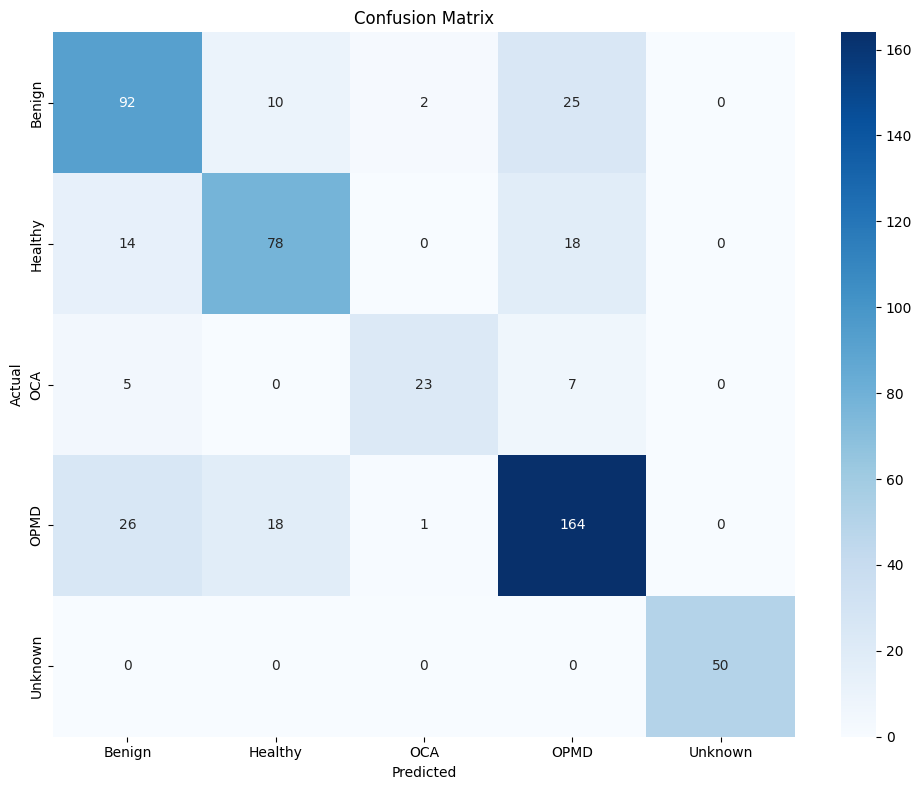

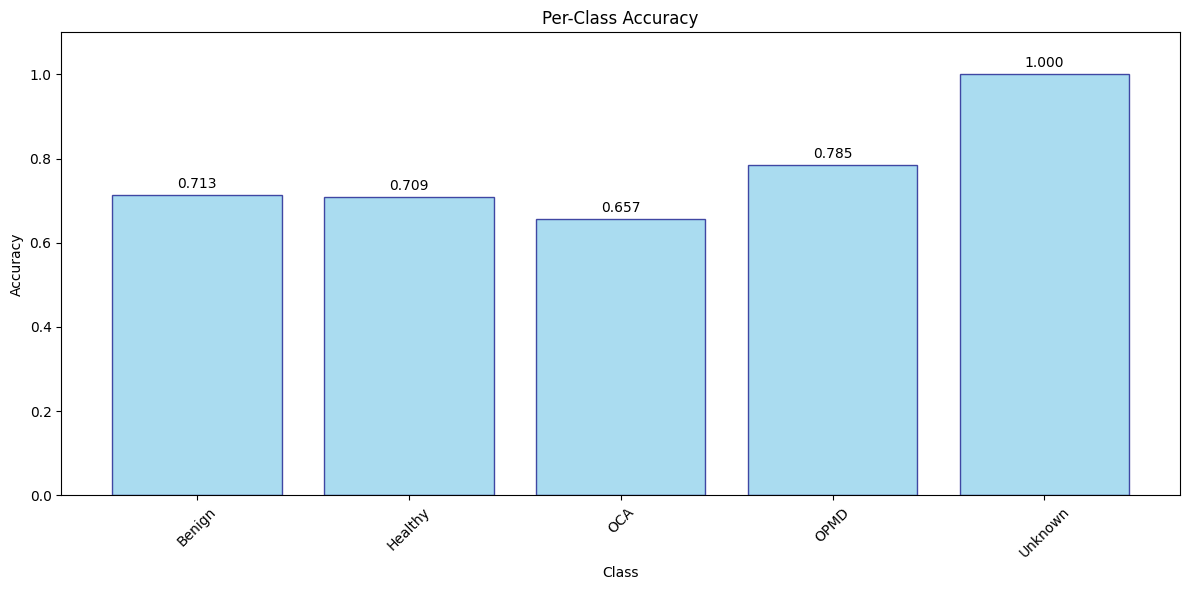

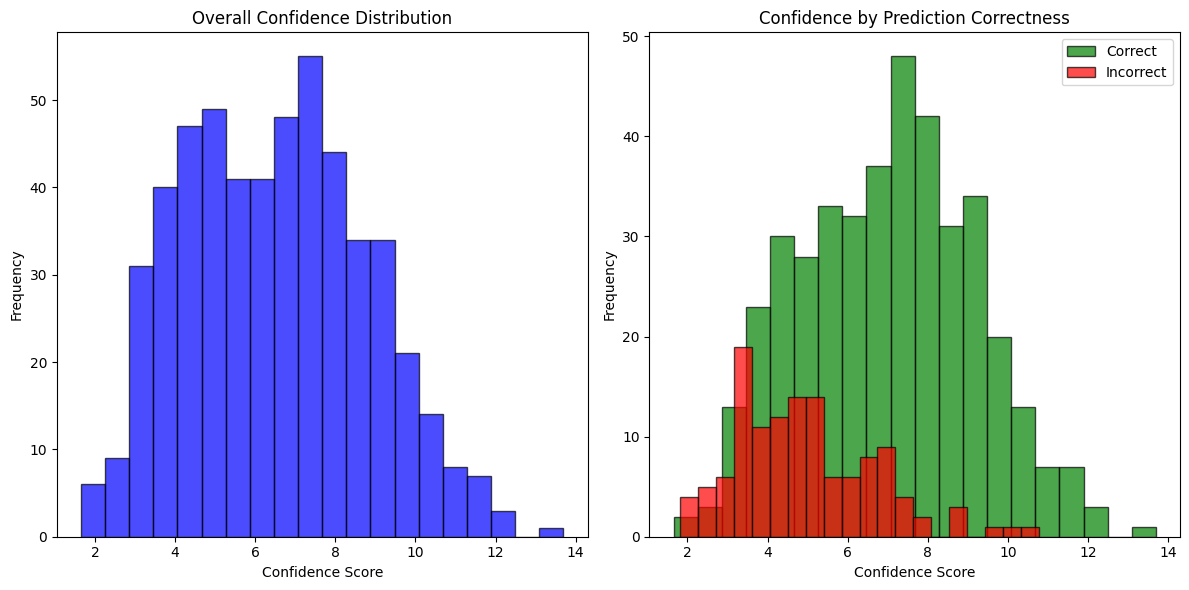

TypeError: Object of type float32 is not JSON serializable

In [ ]:
def plot_confusion_matrix(cm, class_names, title='Confusion Matrix'):
    """Plot confusion matrix"""
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

def plot_per_class_accuracy(per_class_accuracy, title='Per-Class Accuracy'):
    """Plot per-class accuracy"""
    classes = list(per_class_accuracy.keys())
    accuracies = list(per_class_accuracy.values())
    
    plt.figure(figsize=(12, 6))
    bars = plt.bar(classes, accuracies, color='skyblue', edgecolor='navy', alpha=0.7)
    
    # Add value labels on bars
    for bar, acc in zip(bars, accuracies):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{acc:.3f}', ha='center', va='bottom')
    
    plt.title(title)
    plt.xlabel('Class')
    plt.ylabel('Accuracy')
    plt.ylim(0, 1.1)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

def plot_confidence_distribution(results, title='Confidence Distribution'):
    """Plot confidence score distribution"""
    confidences = [r['confidence'] for r in results if r['confidence'] > 0]
    correct_confidences = [r['confidence'] for r in results if r['correct'] and r['confidence'] > 0]
    incorrect_confidences = [r['confidence'] for r in results if not r['correct'] and r['confidence'] > 0]
    
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    plt.hist(confidences, bins=20, alpha=0.7, color='blue', edgecolor='black')
    plt.title('Overall Confidence Distribution')
    plt.xlabel('Confidence Score')
    plt.ylabel('Frequency')
    
    plt.subplot(1, 2, 2)
    plt.hist(correct_confidences, bins=20, alpha=0.7, color='green', label='Correct', edgecolor='black')
    plt.hist(incorrect_confidences, bins=20, alpha=0.7, color='red', label='Incorrect', edgecolor='black')
    plt.title('Confidence by Prediction Correctness')
    plt.xlabel('Confidence Score')
    plt.ylabel('Frequency')
    plt.legend()
    
    plt.tight_layout()
    plt.show()

def generate_report(evaluation_results, output_dir):
    """Generate comprehensive evaluation report"""
    
    if not evaluation_results:
        print("❌ No evaluation results to report")
        return
    
    # Create report directory
    report_dir = Path(output_dir) / "evaluation_report"
    report_dir.mkdir(exist_ok=True)
    
    # Save detailed results as JSON
    results_file = report_dir / "detailed_results.json"
    with open(results_file, 'w') as f:
         json.dump(
        evaluation_results,
        f,
        indent=2,
        default=lambda x: float(x) if isinstance(x, (np.floating,)) else int(x) if isinstance(x, (np.integer,)) else str(x)
    )
    
    # Generate text report
    report_file = report_dir / "evaluation_report.txt"
    with open(report_file, 'w') as f:
        f.write("ORAL CAVITY CLASSIFICATION ENSEMBLE EVALUATION REPORT\n")
        f.write("=" * 60 + "\n\n")
        
        f.write(f"Total Test Samples: {evaluation_results['total_samples']}\n")
        f.write(f"Overall Accuracy: {evaluation_results['accuracy']:.4f}\n")
        f.write(f"Average Confidence: {evaluation_results['avg_confidence']:.4f}\n\n")
        
        f.write("PER-CLASS ACCURACY:\n")
        f.write("-" * 30 + "\n")
        for class_name, acc in evaluation_results['per_class_accuracy'].items():
            f.write(f"{class_name:15}: {acc:.4f}\n")
        
        f.write("\nCLASSIFICATION REPORT:\n")
        f.write("-" * 30 + "\n")
        class_report = evaluation_results['classification_report']
        for class_name in CLASS_NAMES:
            if class_name in class_report:
                metrics = class_report[class_name]
                f.write(f"\n{class_name}:\n")
                f.write(f"  Precision: {metrics['precision']:.4f}\n")
                f.write(f"  Recall:    {metrics['recall']:.4f}\n")
                f.write(f"  F1-Score:  {metrics['f1-score']:.4f}\n")
                f.write(f"  Support:   {metrics['support']}\n")
    
    print(f"📄 Report saved to: {report_dir}")
    print(f"   - Detailed results: {results_file}")
    print(f"   - Text report: {report_file}")
    
    return report_dir

# Generate visualizations and reports
if evaluation_results:
    print("📊 Generating visualizations and reports...")
    
    # Plot confusion matrix
    cm = np.array(evaluation_results['confusion_matrix'])
    plot_confusion_matrix(cm, CLASS_NAMES)
    
    # Plot per-class accuracy
    plot_per_class_accuracy(evaluation_results['per_class_accuracy'])
    
    # Plot confidence distribution
    plot_confidence_distribution(evaluation_results['detailed_results'])
    
    # Generate comprehensive report
    report_dir = generate_report(evaluation_results, OUTPUT_DIR)
    
    print("✅ All visualizations and reports generated!")
else:
    print("❌ No evaluation results available for visualization")


In [ ]:
# Generate comprehensive report
report_dir = generate_report(evaluation_results, OUTPUT_DIR)

📄 Report saved to: /Users/alokdwivedi/dev/github/medpylabs/oral_cavity_classifier_app/ml/training/notebooks/ml/training/results/production_merged/onnx_ensemble_output/evaluation_report
   - Detailed results: /Users/alokdwivedi/dev/github/medpylabs/oral_cavity_classifier_app/ml/training/notebooks/ml/training/results/production_merged/onnx_ensemble_output/evaluation_report/detailed_results.json
   - Text report: /Users/alokdwivedi/dev/github/medpylabs/oral_cavity_classifier_app/ml/training/notebooks/ml/training/results/production_merged/onnx_ensemble_output/evaluation_report/evaluation_report.txt


## 10. Flutter Integration Code Generation


In [ ]:
def generate_flutter_ensemble_code(ensemble, output_dir):
    """Generate Flutter code for the virtual ensemble"""
    
    if not ensemble:
        print("❌ No ensemble available for code generation")
        return
    
    # Create Flutter code directory
    flutter_dir = Path(output_dir) / "flutter_ensemble_code"
    flutter_dir.mkdir(exist_ok=True)
    
    # Generate Dart code for ensemble
    dart_code = f'''
// Generated Flutter ensemble code for {len(ensemble.models)} models
// This code can be integrated into your Flutter app

import 'dart:io';
import 'dart:typed_data';
import 'package:image/image.dart' as img;
import 'package:onnxruntime/onnxruntime.dart';

class VirtualEnsemble {{
  late List<OrtSession> _sessions;
  final List<String> _classNames = {CLASS_NAMES};
  final int _numClasses = {len(CLASS_NAMES)};
  
  VirtualEnsemble() {{
    _sessions = [];
  }}
  
  Future<void> loadModels(List<String> modelPaths) async {{
    for (String path in modelPaths) {{
      try {{
        final session = OrtSession.createFromFile(path);
        _sessions.add(session);
        print('✅ Loaded model: $path');
      }} catch (e) {{
        print('❌ Failed to load $path: $e');
      }}
    }}
    print('🎯 Ensemble loaded with ${{_sessions.length}} models');
  }}
  
  Future<List<double>> preprocessImage(String imagePath) async {{
    // Load and resize image
    final imageBytes = await File(imagePath).readAsBytes();
    final image = img.decodeImage(imageBytes);
    final resized = img.copyResize(image!, width: 224, height: 224);
    
    // Convert to float array and normalize
    final List<double> pixels = [];
    for (int y = 0; y < 224; y++) {{
      for (int x = 0; x < 224; x++) {{
        final pixel = resized.getPixel(x, y);
        final r = img.getRed(pixel) / 255.0;
        final g = img.getGreen(pixel) / 255.0;
        final b = img.getBlue(pixel) / 255.0;
        
        // Normalize using ImageNet stats
        pixels.add((r - 0.485) / 0.229);
        pixels.add((g - 0.456) / 0.224);
        pixels.add((b - 0.406) / 0.225);
      }}
    }}
    
    return pixels;
  }}
  
  Future<Map<String, dynamic>> predictEnsemble(String imagePath, {{String method = 'average'}}) async {{
    if (_sessions.isEmpty) {{
      throw Exception('No models loaded');
    }}
    
    // Preprocess image
    final inputData = await preprocessImage(imagePath);
    final inputTensor = OrtValueTensor.createTensorWithDataList(
      [1, 3, 224, 224], inputData, OrtTensorType.ortTensorTypeFloat
    );
    
    List<List<double>> allPredictions = [];
    
    // Get predictions from all models
    for (OrtSession session in _sessions) {{
      try {{
        final inputs = {{'input': inputTensor}};
        final outputs = session.run(inputs);
        final outputTensor = outputs[0];
        final List<double> probabilities = outputTensor.getValueAsList();
        allPredictions.add(probabilities);
      }} catch (e) {{
        print('❌ Model prediction failed: $e');
        allPredictions.add(List.filled(_numClasses, 0.0));
      }}
    }}
    
    // Combine predictions
    List<double> ensemblePred;
    double confidence;
    
    if (method == 'average') {{
      ensemblePred = List.filled(_numClasses, 0.0);
      for (List<double> pred in allPredictions) {{
        for (int i = 0; i < _numClasses; i++) {{
          ensemblePred[i] += pred[i];
        }}
      }}
      for (int i = 0; i < _numClasses; i++) {{
        ensemblePred[i] /= allPredictions.length;
      }}
    }} else if (method == 'voting') {{
      ensemblePred = List.filled(_numClasses, 0.0);
      for (List<double> pred in allPredictions) {{
        int maxIndex = pred.indexOf(pred.reduce((a, b) => a > b ? a : b));
        ensemblePred[maxIndex]++;
      }}
      for (int i = 0; i < _numClasses; i++) {{
        ensemblePred[i] /= allPredictions.length;
      }}
    }} else {{
      throw Exception('Unsupported ensemble method: $method');
    }}
    
    // Find predicted class
    int predictedClass = ensemblePred.indexOf(ensemblePred.reduce((a, b) => a > b ? a : b));
    String predictedClassName = _classNames[predictedClass];
    confidence = ensemblePred[predictedClass];
    
    return {{
      'probabilities': ensemblePred,
      'predictedClass': predictedClass,
      'predictedClassName': predictedClassName,
      'confidence': confidence,
    }};
  }}
  
  void dispose() {{
    for (OrtSession session in _sessions) {{
      session.release();
    }}
    _sessions.clear();
  }}
}}

// Usage example:
/*
final ensemble = VirtualEnsemble();
await ensemble.loadModels([
  'path/to/model1.onnx',
  'path/to/model2.onnx',
  // ... more models
]);

final result = await ensemble.predictEnsemble('path/to/image.jpg');
print('Predicted: ${{result['predictedClassName']}} (confidence: ${{result['confidence']}})');
*/
'''
    
    # Save Dart code
    dart_file = flutter_dir / "virtual_ensemble.dart"
    with open(dart_file, 'w') as f:
        f.write(dart_code)
    
    # Generate model paths list
    model_paths = [str(model_path) for model_path in onnx_models]
    model_paths_file = flutter_dir / "model_paths.json"
    with open(model_paths_file, 'w') as f:
        json.dump(model_paths, f, indent=2)
    
    # Generate pubspec.yaml dependencies
    pubspec_content = '''
name: oral_cavity_ensemble
description: Flutter app with ONNX ensemble for oral cavity classification

dependencies:
  flutter:
    sdk: flutter
  onnxruntime: ^1.12.0
  image: ^4.0.17
  path_provider: ^2.1.1

dev_dependencies:
  flutter_test:
    sdk: flutter
  flutter_lints: ^3.0.0

flutter:
  uses-material-design: true
'''
    
    pubspec_file = flutter_dir / "pubspec.yaml"
    with open(pubspec_file, 'w') as f:
        f.write(pubspec_content)
    
    # Generate README
    readme_content = f'''
# Flutter ONNX Ensemble Integration

This directory contains the generated Flutter code for integrating the {len(ensemble.models)}-model ensemble.

## Files:
- `virtual_ensemble.dart`: Main ensemble class
- `model_paths.json`: List of ONNX model paths
- `pubspec.yaml`: Flutter dependencies

## Setup:
1. Copy the ONNX model files to your Flutter app's assets
2. Update the model paths in `model_paths.json`
3. Add the dependencies to your `pubspec.yaml`
4. Import and use the `VirtualEnsemble` class

## Usage:
```dart
final ensemble = VirtualEnsemble();
await ensemble.loadModels(modelPaths);
final result = await ensemble.predictEnsemble(imagePath);
```

## Ensemble Methods:
- `average`: Simple averaging of predictions
- `voting`: Hard voting based on predicted classes

## Class Names:
{CLASS_NAMES}
'''
    
    readme_file = flutter_dir / "README.md"
    with open(readme_file, 'w') as f:
        f.write(readme_content)
    
    print(f"📱 Flutter integration code generated in: {flutter_dir}")
    print(f"   - Dart code: {dart_file}")
    print(f"   - Model paths: {model_paths_file}")
    print(f"   - Dependencies: {pubspec_file}")
    print(f"   - Documentation: {readme_file}")
    
    return flutter_dir

# Generate Flutter integration code
if ensemble:
    flutter_code_dir = generate_flutter_ensemble_code(ensemble, OUTPUT_DIR)
    print("✅ Flutter integration code ready!")
else:
    print("❌ No ensemble available for Flutter code generation")


In [ ]:
def convert_pytorch_to_onnx(pytorch_model_path, onnx_model_path, input_shape=(1, 3, 224, 224)):
    """Convert PyTorch model to ONNX format"""
    
    print(f"🔄 Converting {pytorch_model_path.name} to ONNX...")
    
    try:
        # Load PyTorch model
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        model = torch.load(pytorch_model_path, map_location=device)
        
        # Set model to evaluation mode
        model.eval()
        
        # Create dummy input
        dummy_input = torch.randn(input_shape).to(device)
        
        # Export to ONNX
        torch.onnx.export(
            model,
            dummy_input,
            onnx_model_path,
            export_params=True,
            opset_version=11,
            do_constant_folding=True,
            input_names=['input'],
            output_names=['output'],
            dynamic_axes={
                'input': {0: 'batch_size'},
                'output': {0: 'batch_size'}
            }
        )
        
        print(f"✅ Successfully converted to {onnx_model_path}")
        return True
        
    except Exception as e:
        print(f"❌ Conversion failed: {e}")
        return False

def test_onnx_model(onnx_model_path, test_input_shape=(1, 3, 224, 224)):
    """Test ONNX model with dummy input"""
    
    try:
        # Load ONNX model
        ort_session = ort.InferenceSession(onnx_model_path)
        
        # Create test input
        test_input = np.random.randn(*test_input_shape).astype(np.float32)
        
        # Run inference
        outputs = ort_session.run(None, {'input': test_input})
        
        print(f"✅ ONNX model test successful")
        print(f"   Input shape: {test_input.shape}")
        print(f"   Output shape: {outputs[0].shape}")
        print(f"   Output classes: {len(outputs[0][0])}")
        
        return True
        
    except Exception as e:
        print(f"❌ ONNX model test failed: {e}")
        return False

# Convert all PyTorch models to ONNX
conversion_results = []
onnx_models = []

for pytorch_model in pytorch_models:
    onnx_model_path = Path(OUTPUT_DIR) / f"{pytorch_model.stem}.onnx"
    
    # Convert to ONNX
    success = convert_pytorch_to_onnx(pytorch_model, onnx_model_path)
    
    if success:
        # Test the converted model
        test_success = test_onnx_model(onnx_model_path)
        
        conversion_results.append({
            'pytorch_path': str(pytorch_model),
            'onnx_path': str(onnx_model_path),
            'conversion_success': success,
            'test_success': test_success
        })
        
        if test_success:
            onnx_models.append(onnx_model_path)

print(f"\n📊 Conversion Summary:")
print(f"   Total models: {len(pytorch_models)}")
print(f"   Successfully converted: {len(onnx_models)}")
print(f"   Failed: {len(pytorch_models) - len(onnx_models)}")


## Like-for-like: Virtual Ensemble on frozen binary test sets (T5, TB, TM)

**Goal:** Compare the **best Virtual Ensemble** (76.36% on 5-class test) with the **best binary merged TFLite** (63.07% on merged test) using the **same** evaluation framework.

- **T5**: 5-class-only test (binary view: OCA+OPMD=1, Benign+Healthy=0).
- **TB**: Binary-only test (15% holdout from binary dataset).
- **TM**: Mixed = T5 ∪ TB (main comparable metric).

**Prerequisite:** Build frozen manifests once: from `ml/training/notebooks` run  
`python frozen_test_sets.py` (or call `build_and_save_frozen_sets()` with your 5-class and binary dataset paths).

Then run the evaluator on the Ensemble (ONNX dir = project `assets/` or this notebook's `OUTPUT_DIR`):

```bash
cd ml/training/notebooks
python evaluate_on_frozen_sets.py --model ../../../assets --model_type 5class_onnx_ensemble --output results/ensemble_frozen_T5_TB_TM.json
```

To get binary merged TFLite on the same sets (for comparison):

```bash
python evaluate_on_frozen_sets.py --model results/binary_merged/run_20260129_173447/tflite/binary_merged_dynamic.tflite --model_type binary_tflite --output results/binary_merged_frozen_T5_TB_TM.json
```

In [11]:
# Run Virtual Ensemble on frozen test sets T5, TB, TM (like-for-like with binary merged TFLite)
# Requires: frozen_test_sets/ with T5.json, TB.json, TM.json (run frozen_test_sets.py first)
import subprocess
import sys
from pathlib import Path

NOTEBOOK_DIR = Path(".").resolve()
# ml/training/notebooks -> repo root is parent.parent.parent
REPO_ROOT = NOTEBOOK_DIR.parent.parent.parent
ASSETS_DIR = REPO_ROOT / "assets"
FROZEN_DIR = NOTEBOOK_DIR / "frozen_test_sets"
OUT_RESULTS = NOTEBOOK_DIR / "results"
OUT_RESULTS.mkdir(parents=True, exist_ok=True)

# Path to ensemble ONNX models (project assets or this notebook's OUTPUT_DIR)
onnx_dir = ASSETS_DIR if (ASSETS_DIR / "ensemble_model_1.onnx").exists() else Path(OUTPUT_DIR)
if not (onnx_dir / "ensemble_model_1.onnx").exists():
    print("Skip: ensemble ONNX not found in assets/ or OUTPUT_DIR. Run conversion cells first or copy ONNX to assets/.")
else:
    cmd = [
        sys.executable,
        str(NOTEBOOK_DIR / "evaluate_on_frozen_sets.py"),
        "--model", str(onnx_dir),
        "--model_type", "5class_onnx_ensemble",
        "--frozen_dir", str(FROZEN_DIR),
        "--output", str(OUT_RESULTS / "ensemble_frozen_T5_TB_TM.json"),
    ]
    print("Running:", " ".join(cmd))
    result = subprocess.run(cmd, cwd=str(NOTEBOOK_DIR))
    if result.returncode != 0:
        print("If frozen sets missing, run: python frozen_test_sets.py")
    else:
        print("Done. Compare TM accuracy with binary merged 63.07% (run binary TFLite with evaluate_on_frozen_sets.py --model_type binary_tflite).")

Running: /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/venv_pytorch/bin/python3.11 /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/evaluate_on_frozen_sets.py --model /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/assets --model_type 5class_onnx_ensemble --frozen_dir /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/frozen_test_sets --output /Users/alokdwivedi/dev/github/3amwave/oral-cavity-classifier/ml/training/notebooks/results/ensemble_frozen_T5_TB_TM.json
Running on T5...
Running on TB...
Running on TM...

Frozen test sets: T5, TB, TM
T5 (5-class test):  n=484  Acc=81.40%  Sens=81.63%  Spec=81.17%
TB (binary test):   n=246  Acc=74.39%  Sens=65.41%  Spec=84.96%
TM (mixed):         n=730  Acc=79.04%  Sens=75.93%  Spec=82.39%
TM per-source:
  Source A (5-class): Acc=81.40%  Sens=81.63%  Spec=81.17%
  Source B (binary): Acc=74.39%  Sens=65.41%  Spec=84.96%

Results saved to: /Us